<a href="https://colab.research.google.com/github/hoseking86/GTZAN-Assignment2/blob/main/GTZAN_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**NB2.1 Accessing the GTZAN Dataset**

This section imports the required Python libraries and confirms that the GTZAN dataset is accessible through Google Drive

In [1]:
#Library imports
import os
from joblib import Parallel, delayed
from tqdm.auto import tqdm
import pandas as pd
import librosa
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
#Import the libraries required for dataset splitting and optional scaling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
#Import the libraries required for five-fold cross-validation
from sklearn.model_selection import StratifiedKFold, cross_val_score
#Import the Decision Tree and Random Forest classifiers
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
#GridSearchCV for hyperparameter optimisation
from sklearn.model_selection import GridSearchCV, StratifiedKFold
#Import the libraries required to generate learning curves
from sklearn.model_selection import learning_curve, StratifiedKFold
import numpy as np
import matplotlib.pyplot as plt
#Import evaluation metrics for final model testing
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

#Import libraries for displaying results
import pandas as pd
import matplotlib.pyplot as plt



In [2]:
#Google drive mounting
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
#Define the path to the GTZAN dataset
dataset_path = "/content/drive/MyDrive/datasets/music_genre"

In [4]:
#Check that the data folder is accessible
!ls "/content/drive/MyDrive/datasets/music_genre"

blues  classical  country  disco  hiphop  jazz	metal  pop  reggae  rock


**NB2.2 Dataset Organisation**

This section organises the GTZAN audio files according to their genres and records the file paths required for feature extraction

In [5]:
#Identify the genre folders
genres = [d.lower() for d in os.listdir(dataset_path)]
genres

['rock',
 'classical',
 'metal',
 'reggae',
 'jazz',
 'country',
 'hiphop',
 'blues',
 'disco',
 'pop']

In [6]:
#Dictionary to store the clips path by genre
audio_files_by_genre = {genre: [] for genre in genres}

#Collect the audio files from each genre folder
for genre in genres:
  genre_path = os.path.join(dataset_path, genre)
  for f in os.listdir(genre_path):
    audio_files_by_genre[genre].append(os.path.join(genre_path, f))

In [7]:
#Display the number of audio files in each genre
for genre, files in audio_files_by_genre.items():
    print(genre, len(files))

rock 100
classical 100
metal 100
reggae 100
jazz 99
country 100
hiphop 100
blues 100
disco 100
pop 100


**NB2.3 Audio Feature Extraction**

This section extracts numerical audio features from the GTZAN recordings using Librosa. The extracted features are combined into a Pandas DataFrame for subsequent validation and machine learning

In [8]:
#Setting the sampling rate
#22kHz is sampling rate of the audio-files
SR = 22050

In [9]:
def extract_features(audio_file, genre, sr=SR):
    """Extract one row of features from a single audio file."""
    try:
        y, sr = librosa.load(audio_file, sr=sr)
    except Exception as e:
        return {'file': audio_file, 'genre': genre, 'error': str(e)}

    # Compute the STFT once and reuse it for every spectral feature
    S = np.abs(librosa.stft(y))                          # magnitude spectrogram
    S_power = S ** 2
    log_mel = librosa.power_to_db(librosa.feature.melspectrogram(S=S_power, sr=sr))

    # Tempo: reuse the log-mel for the onset envelope; skip full beat tracking
    onset_env = librosa.onset.onset_strength(S=log_mel, sr=sr)
    tempo = librosa.feature.tempo(onset_envelope=onset_env, sr=sr)[0]

    centroid = librosa.feature.spectral_centroid(S=S, sr=sr)
    mfcc_means = librosa.feature.mfcc(S=log_mel, n_mfcc=13).mean(axis=1)

    row = {
        'file': audio_file,
        'genre': genre,
        'tempo': float(tempo),
        # Spectral features
        'spectral_centroid_mean': float(centroid.mean()),
        'spectral_centroid_std': float(centroid.std()),
        'spectral_bandwidth_mean': float(librosa.feature.spectral_bandwidth(S=S, sr=sr).mean()),
        'spectral_rolloff_mean': float(librosa.feature.spectral_rolloff(S=S, sr=sr).mean()),
        'spectral_flatness_mean': float(librosa.feature.spectral_flatness(S=S).mean()),
        # Tonal / pitch features
        'chroma_mean': float(librosa.feature.chroma_stft(S=S_power, sr=sr).mean()),
    }
    # Timbral features (MFCCs aggregated per coefficient)
    row.update({f'mfcc_{i}_mean': float(c) for i, c in enumerate(mfcc_means, start=1)})
    return row

# Extracts features from multiple files parallely
def load_dataset(n_jobs=-1):
    jobs = [(f, g) for g, files in audio_files_by_genre.items() for f in files]

    results = Parallel(n_jobs=n_jobs, return_as="generator")(
        delayed(extract_features)(f, g) for f, g in jobs
    )
    rows = list(tqdm(results, total=len(jobs), desc="Extracting features", unit="file"))

    df = pd.DataFrame(rows)
    if 'error' in df.columns:
        failed = df[df['error'].notna()]
        print(f"Skipped {len(failed)} unreadable file(s):")
        for f, err in zip(failed['file'], failed['error']):
            print(f"  {f}: {err}")
        df = df[df['error'].isna()].drop(columns='error').reset_index(drop=True)
    return df

In [10]:
#Extraction of the features and display the first five records
df = load_dataset()
df.head()

Extracting features:   0%|          | 0/999 [00:00<?, ?file/s]

,file,genre,tempo,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,spectral_rolloff_mean,spectral_flatness_mean,chroma_mean,mfcc_1_mean,...,mfcc_4_mean,mfcc_5_mean,mfcc_6_mean,mfcc_7_mean,mfcc_8_mean,mfcc_9_mean,mfcc_10_mean,mfcc_11_mean,mfcc_12_mean,mfcc_13_mean
0,/content/drive/MyDrive/datasets/music_genre/ro...,rock,129.199219,2334.519061,336.228937,2208.060155,4819.107544,0.009506,0.392994,-42.662823,...,44.516602,-11.996202,25.576914,-22.668953,28.336857,-19.271856,21.482964,-15.258891,11.748107,-11.575924
1,/content/drive/MyDrive/datasets/music_genre/ro...,rock,99.384014,2975.773811,544.323802,2423.205316,5926.535367,0.021068,0.382693,-95.446480,...,44.241337,-22.469748,29.748888,-21.573271,23.954361,-16.577047,20.471979,-19.630770,13.887503,-12.625713
2,/content/drive/MyDrive/datasets/music_genre/ro...,rock,123.046875,2116.145602,435.115390,2245.391435,4689.983267,0.006532,0.378740,-119.150978,...,58.555363,-12.933258,26.834330,-17.646807,19.371737,-15.605269,13.570684,-16.671040,11.870044,-12.196166
3,/content/drive/MyDrive/datasets/music_genre/ro...,rock,123.046875,1711.169295,1238.594812,2309.187256,3491.701315,0.010117,0.329639,-302.824310,...,25.962639,18.715103,7.566854,7.333934,4.033652,-4.181990,0.879667,0.954835,2.820901,1.406351
4,/content/drive/MyDrive/datasets/music_genre/ro...,rock,112.347147,2511.714306,626.831829,2245.075054,5129.615334,0.006721,0.367960,-202.223434,...,66.306335,-8.287852,24.383793,-16.236677,17.128633,-21.286032,3.962978,-19.760389,0.482673,-4.509064


**NB2.4 Dataset Validation**


This section validates the extracted dataset by checking its dimensions, genre distribution, missing values and duplicate records before splitting it into training and testing datasets

In [11]:
#Checking the extracted dataset for the expected shape
print("Dataset shape:", df.shape)
print("Genre counts:")
print(df["genre"].value_counts())
print("Missing values:", df.isnull().sum().sum())

#Checking for duplications
print("Duplicate file paths:", df["file"].duplicated().sum())

feature_columns = df.drop(columns=["file", "genre"]).columns

print("Duplicate feature rows:",
      df.duplicated(subset=feature_columns).sum())



Dataset shape: (999, 22)
Genre counts:
genre
rock         100
classical    100
metal        100
reggae       100
country      100
hiphop       100
disco        100
blues        100
pop          100
jazz          99
Name: count, dtype: int64
Missing values: 0
Duplicate file paths: 0
Duplicate feature rows: 14


**NB2.5 Training and Testing Dataset Split**

This section divides the validated dataset into 70% training and 30% testing data using stratified sampling to maintain similar genre proportions. Feature scaling is disabled, and a fixed random state is used to support reproducibility

In [12]:
#Import the libraries required for dataset splitting and optional scaling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


def split_dataset(df, test_size=0.2, target='genre', drop_cols=('file',),
                  stratify=True, scale=True, random_state=42, verbose=True):
    """
    Split the feature DataFrame into train and test sets.

    Parameters
    ----------
    df           : DataFrame returned by load_dataset()
    test_size    : share of data for testing; a fraction (0.2) or a percentage (20)
    target       : name of the label column
    drop_cols    : non-feature columns to exclude (e.g. file paths)
    stratify     : keep the genre proportions the same in train and test
    scale        : standardise features (mean 0, std 1); scaler is fit on train only
    random_state : seed so the split is reproducible
    verbose      : print a summary of the split

    Returns
    -------
    X_train, X_test, y_train, y_test, scaler (None if scale=False)
    """
    if 1 < test_size < 100:          # allow percentages like 20 or 30
        test_size = test_size / 100
    if not 0 < test_size < 1:
        raise ValueError("test_size must be a fraction (0–1) or a percentage (1–99).")

    X = df.drop(columns=[target, *drop_cols], errors='ignore')
    y = df[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        stratify=y if stratify else None,
        random_state=random_state,
    )

    scaler = None
    if scale:
        scaler = StandardScaler().fit(X_train)
        X_train = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
        X_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

    if verbose:
        print(f"Train: {len(X_train)} samples | Test: {len(X_test)} samples "
              f"| Features: {X.shape[1]} | Test share: {test_size:.0%}")
        print("\nSamples per genre:")
        print(pd.DataFrame({'train': y_train.value_counts(),
                            'test': y_test.value_counts()}).sort_index())

    return X_train, X_test, y_train, y_test, scaler

In [13]:
#Create a reproducible 70/30 stratified split without feature scaling
X_train, X_test, y_train, y_test, _ = split_dataset(df, test_size=30, scale=False)

Train: 699 samples | Test: 300 samples | Features: 20 | Test share: 30%

Samples per genre:
           train  test
genre                 
blues         70    30
classical     70    30
country       70    30
disco         70    30
hiphop        70    30
jazz          69    30
metal         70    30
pop           70    30
reggae        70    30
rock          70    30


**NB2.6 Training and Testing Data Validation**

This section checks the training and testing datasets to confirm their dimensions, missing values, separation and genre distributions. These checks help verify that the datasets have been prepared correctly before model training

In [14]:
#Display the dimensions of the training and testing datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

#Check for missing values in the feature datasets
print("Missing training values:", X_train.isnull().sum().sum())
print("Missing testing values:", X_test.isnull().sum().sum())

#Confirm that the training and testing datasets have no shared row indices
print("Shared row indices:",
      len(set(X_train.index) & set(X_test.index)))

Training features: (699, 20)
Testing features: (300, 20)
Training labels: (699,)
Testing labels: (300,)
Missing training values: 0
Missing testing values: 0
Shared row indices: 0


In [15]:
#Preview the training features and labels
X_train.head()

,tempo,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,spectral_rolloff_mean,spectral_flatness_mean,chroma_mean,mfcc_1_mean,mfcc_2_mean,mfcc_3_mean,mfcc_4_mean,mfcc_5_mean,mfcc_6_mean,mfcc_7_mean,mfcc_8_mean,mfcc_9_mean,mfcc_10_mean,mfcc_11_mean,mfcc_12_mean,mfcc_13_mean
365,151.999081,2006.849364,524.748730,2120.295215,4323.369243,0.007424,0.390109,-88.075615,109.439316,-25.164967,40.395290,-8.778365,24.714594,-11.525630,18.510265,-8.291809,17.030918,-8.433278,9.799047,-12.903516
547,151.999081,1729.788587,749.306445,2247.607733,3359.521088,0.008072,0.360097,-162.780792,119.890144,-2.907841,20.508930,27.810158,5.490170,6.040869,1.191267,-3.696575,0.352279,4.416835,-0.410248,2.456137
110,123.046875,877.322540,180.951747,1109.262449,1457.712918,0.000354,0.274368,-392.924988,190.735046,-13.309890,8.256798,1.556012,-11.073181,-11.240291,-13.994958,-10.621299,-9.390467,-4.621174,-10.071729,-4.821782
128,117.453835,1285.370259,358.633657,1660.391744,2477.151043,0.001742,0.279380,-360.838684,138.970856,-12.927217,33.778614,7.596159,-1.708812,1.027019,4.072128,3.938996,0.941578,0.516648,4.686481,3.336596
603,107.666016,1963.064381,821.914877,1917.402331,3798.453701,0.008347,0.430894,-138.880600,100.207207,-31.442926,32.449326,-2.751766,13.091758,-14.506294,13.943220,-15.174354,8.177486,-4.925512,3.508959,-7.984948


In [16]:
#Preview the training features and labels
y_train.head()

,genre
365,reggae
547,country
110,classical
128,classical
603,hiphop


In [17]:
#Check that genre proportions are maintained after splitting
print("Training genre distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting genre distribution:")
print(y_test.value_counts().sort_index())

Training genre distribution:
genre
blues        70
classical    70
country      70
disco        70
hiphop       70
jazz         69
metal        70
pop          70
reggae       70
rock         70
Name: count, dtype: int64

Testing genre distribution:
genre
blues        30
classical    30
country      30
disco        30
hiphop       30
jazz         30
metal        30
pop          30
reggae       30
rock         30
Name: count, dtype: int64


**NB2.7	Decision Tree and Random Forest Pipelines**

This section creates Decision Tree (DT) and Random Forest (RF) classification pipelines using scikit-learn and lecture materials and refernece points. Both pipelines combine the preprocessing steps, where required and the relevant classifiers into separate workflows. This helps to prevent data leakage by ensuring that any preprocessing is fitted using only the training data. A fixed random seed is also used for both models to ensure that the results can be reproduced

In [18]:
# Set the random seed for reproducibility
RANDOM_STATE = 42

# Create the Decision Tree pipeline
dt_pipeline = make_pipeline(
    # This is used to replace missing numerical values although there are not any in the dataset
    # This is being added as a precuationary measure
    SimpleImputer(strategy="median"),
    DecisionTreeClassifier(random_state=RANDOM_STATE)
)

# Create the Random Forest pipeline
rf_pipeline = make_pipeline(
    # This is used to replace missing numerical values although there are not any in the dataset
    # This is being added as a precuationary measure
    SimpleImputer(strategy="median"),
    RandomForestClassifier(random_state=RANDOM_STATE)
)

# Display the two pipelines
display(dt_pipeline)
display(rf_pipeline)

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(random_state=42))])

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('randomforestclassifier',
                 RandomForestClassifier(random_state=42))])

**NB2.8	Model Training and Initial Verification**

This section trains DT and RF models using the training data from the GTZAN dataset. Both models are trained using their respective pipelines to ensure that any preprocessing is carried out using only the training data. Initial checks are then carried out to confirm that both models have been trained successfully and can predict music genres before moving on to further testing and optimisation

In [19]:
#Both the models are using default hyperparameters at this point
#DT - This is where Gini impurity is used to determine splits
#RF - Combine predictions from multiple DTs
#Concepts applied are discussed in Assignment 1

#Train the DT model using the training data
dt_pipeline.fit(X_train, y_train)

#Train the RF model using the same training data
rf_pipeline.fit(X_train, y_train)

#Confirm both models have been trained
print("Decision Tree training completed")
print("Random Forest training completed")

Decision Tree training completed
Random Forest training completed


In [20]:
#Here the trained models are predicting genres from the audio features that have been extracted
#Five recordings are selected from the training data to check both the models can make predictions

#Select the first five recordings from the training data
sample_features = X_train.iloc[:5]

#Generate predictions using both trained models
dt_predictions = dt_pipeline.predict(sample_features)
rf_predictions = rf_pipeline.predict(sample_features)

#Display the actual genres and predicted genres
print("Actual genres:", y_train.iloc[:5].tolist())
print("Decision Tree predictions:", dt_predictions)
print("Random Forest predictions:", rf_predictions)

Actual genres: ['reggae', 'country', 'classical', 'classical', 'hiphop']
Decision Tree predictions: ['reggae' 'country' 'classical' 'classical' 'hiphop']
Random Forest predictions: ['reggae' 'country' 'classical' 'classical' 'hiphop']


In [21]:
# Check that both models return five predictions
assert len(dt_predictions) == 5
assert len(rf_predictions) == 5

# Check that predicted genres exist in the training labels
assert set(dt_predictions).issubset(set(y_train))
assert set(rf_predictions).issubset(set(y_train))

print("Both models passed initial verification")

Both models passed initial verification


**NB3 Model Optimisation and Hyperparameters**

This section looks at optimising the Decision Tree (DT) and Random Forest (RF) models. Their initial performance will be recorded before using hyperparameter tuning and cross-validation to identify the most suitable settings for each model. To align with the assignment requirements, the searches carried out, their results and computational costs will be recorded. Learning curves will also be used to examine how the performance of both models changes as the amount of training data increases.

**NB3.1 — Baseline Model Performance Using Original Model Configurations**

This section uses the original configurations of the Decision Tree (DT) and Random Forest (RF) models to calculate their average classification accuracy using five-fold cross-validation. The results will be used to establish a baseline for comparing the performance of both models against any improvements made during the optimisation process

In [22]:
#This code section sets up five-fold stratified cross-validation
#For DT and RF the same folds will be used

    #Same proprtion of music genres in each of the folds (approximately)
cv = StratifiedKFold(
    #This devides the trainin data into five folds
    n_splits=5,
    #Shuffles the data before any folds are created
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Five-fold stratified cross-validation configured")


Five-fold stratified cross-validation configured


In [23]:
#This section is establishing the Decision Tree baseline using five-fold cross-validation
#Please note only the training dataset is used

dt_baseline_scores = cross_val_score(
    dt_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

# Display the results
print("Decision Tree fold scores:", dt_baseline_scores)
print("Decision Tree mean accuracy:", dt_baseline_scores.mean())
print("Decision Tree standard deviation:", dt_baseline_scores.std())


Decision Tree fold scores: [0.46428571 0.45714286 0.45714286 0.45714286 0.41726619]
Decision Tree mean accuracy: 0.45059609455292904
Decision Tree standard deviation: 0.016893008753829115


In [24]:
#This section is establishing the Decision Tree baseline using five-fold cross-validation
#Please note only the training dataset is used

rf_baseline_scores = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

# Display the results
print("Random Forest fold scores:", rf_baseline_scores)
print("Random Forest mean accuracy:", rf_baseline_scores.mean())
print("Random Forest standard deviation:", rf_baseline_scores.std())

Random Forest fold scores: [0.59285714 0.57142857 0.62142857 0.60714286 0.60431655]
Random Forest mean accuracy: 0.5994347379239466
Random Forest standard deviation: 0.016700814293253305


In [25]:
#This code creates a table which can be used to compare the baseline performances of both models

baseline_results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Mean Accuracy": [
        dt_baseline_scores.mean(),
        rf_baseline_scores.mean()
    ],
    "Standard Deviation": [
        dt_baseline_scores.std(),
        rf_baseline_scores.std()
    ]
})

# Display results to three decimal places
display(baseline_results.round(3))


,Model,Mean Accuracy,Standard Deviation
0,Decision Tree,0.451,0.017
1,Random Forest,0.599,0.017


**NB3.2 Hyperparameter Selection**

This section sets out to detail the hyperparameters values that will be used to optimise DT and RF. The allocated values are to be used during GridSearchCV and five-fold cross-validation

In [26]:
# Display the default Decision Tree hyperparameters
dt_defaults = DecisionTreeClassifier().get_params()

print("Decision Tree defaults:")
print("max_depth:", dt_defaults["max_depth"])
print("min_samples_split:", dt_defaults["min_samples_split"])
print("min_samples_leaf:", dt_defaults["min_samples_leaf"])

# Display the default Random Forest hyperparameters
rf_defaults = RandomForestClassifier().get_params()

print("\nRandom Forest defaults:")
print("n_estimators:", rf_defaults["n_estimators"])
print("max_depth:", rf_defaults["max_depth"])
print("min_samples_leaf:", rf_defaults["min_samples_leaf"])

Decision Tree defaults:
max_depth: None
min_samples_split: 2
min_samples_leaf: 1

Random Forest defaults:
n_estimators: 100
max_depth: None
min_samples_leaf: 1


**NB3.3 Hyperparameter Optimisation (GridSearchCV)**

This section is using GridSearchCV along with the five-fold vlaidation process. The process sets out to test the chosen hyperparameters for both models.

Only training data is being used and the test data is remaining for the final evaluation process

In [27]:
# Define the Decision Tree hyperparameter search values
dt_param_grid = {
    "decisiontreeclassifier__max_depth": [3, 5, 10, 15, 20, None],
    "decisiontreeclassifier__min_samples_leaf": [1, 2, 4],
    "decisiontreeclassifier__min_samples_split": [2, 5, 10]
}

# Define the Random Forest hyperparameter search values
rf_param_grid = {
    "randomforestclassifier__max_depth": [5, 10, 15, 20, None],
    "randomforestclassifier__min_samples_leaf": [1, 2, 4],
    "randomforestclassifier__n_estimators": [100, 200, 400]
}

# Display the selected search values
print("Decision Tree search values:", dt_param_grid)
print("Random Forest search values:", rf_param_grid)

Decision Tree search values: {'decisiontreeclassifier__max_depth': [3, 5, 10, 15, 20, None], 'decisiontreeclassifier__min_samples_leaf': [1, 2, 4], 'decisiontreeclassifier__min_samples_split': [2, 5, 10]}
Random Forest search values: {'randomforestclassifier__max_depth': [5, 10, 15, 20, None], 'randomforestclassifier__min_samples_leaf': [1, 2, 4], 'randomforestclassifier__n_estimators': [100, 200, 400]}


In [28]:
#The hyperparameter search ranges for Decision Tree are defined in this code cell
dt_param_grid = {
    "decisiontreeclassifier__max_depth": [3, 5, 10, 15, 20, None],
    "decisiontreeclassifier__min_samples_leaf": [1, 2, 4],
    "decisiontreeclassifier__min_samples_split": [2, 5, 10]
}

In [29]:
#Create five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [30]:
#Create GridSearchCV for Decision Tree
dt_grid_search = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

In [31]:
#Run GridSearchCV using the training data only
dt_grid_search.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('simpleimputer',
                                        SimpleImputer(strategy='median')),
                                       ('decisiontreeclassifier',
                                        DecisionTreeClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'decisiontreeclassifier__max_depth': [3, 5, 10, 15, 20,
                                                               None],
                         'decisiontreeclassifier__min_samples_leaf': [1, 2, 4],
                         'decisiontreeclassifier__min_samples_split': [2, 5,
                                                                       10]},
             scoring='accuracy')

In [32]:
#Display the best Decision Tree settings and accuracy
print("Decision Tree best parameters:")
print(dt_grid_search.best_params_)

print("Decision Tree best cross-validation accuracy:")
print(dt_grid_search.best_score_)

Decision Tree best parameters:
{'decisiontreeclassifier__max_depth': 15, 'decisiontreeclassifier__min_samples_leaf': 4, 'decisiontreeclassifier__min_samples_split': 10}
Decision Tree best cross-validation accuracy:
0.4649229188078109


In [33]:
# Record the best Decision Tree results
dt_best_params = dt_grid_search.best_params_
dt_best_score = dt_grid_search.best_score_

print("Decision Tree optimisation complete")
print(f"Best accuracy: {dt_best_score:.2%}")

Decision Tree optimisation complete
Best accuracy: 46.49%


In [34]:
# Define the hyperparameter search ranges for Random Forest
rf_param_grid = {
    "randomforestclassifier__max_depth": [3, 5, 10, 15, 20, None],
    "randomforestclassifier__min_samples_leaf": [1, 2, 4],
    "randomforestclassifier__n_estimators": [50, 100, 200]
}

In [35]:
# Create GridSearchCV for Random Forest
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

In [36]:
# Run GridSearchCV using the training data only
rf_grid_search.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('simpleimputer',
                                        SimpleImputer(strategy='median')),
                                       ('randomforestclassifier',
                                        RandomForestClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'randomforestclassifier__max_depth': [3, 5, 10, 15, 20,
                                                               None],
                         'randomforestclassifier__min_samples_leaf': [1, 2, 4],
                         'randomforestclassifier__n_estimators': [50, 100,
                                                                  200]},
             scoring='accuracy')

In [37]:
# Display the best Random Forest settings and accuracy
print("Random Forest best parameters:")
print(rf_grid_search.best_params_)

print("Random Forest best cross-validation accuracy:")
print(rf_grid_search.best_score_)

Random Forest best parameters:
{'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__n_estimators': 50}
Random Forest best cross-validation accuracy:
0.6137204522096609


In [38]:
# Record the best Random Forest results
rf_best_params = rf_grid_search.best_params_
rf_best_score = rf_grid_search.best_score_

print("Random Forest optimisation complete")
print(f"Best accuracy: {rf_best_score:.2%}")

Random Forest optimisation complete
Best accuracy: 61.37%


In [39]:
print("Random Forest best parameters:")
print(rf_grid_search.best_params_)

Random Forest best parameters:
{'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__n_estimators': 50}


In [40]:
# Display the mean fitting time for the best combination
print("Decision Tree mean fitting time:")
print(dt_grid_search.cv_results_["mean_fit_time"][
    dt_grid_search.best_index_
])

print("Random Forest mean fitting time:")
print(rf_grid_search.cv_results_["mean_fit_time"][
    rf_grid_search.best_index_
])

Decision Tree mean fitting time:
0.048279523849487305
Random Forest mean fitting time:
0.29968905448913574


**NB3.4.1 Optimisation Results**

In [41]:
#Create a table showing the best hyperparameters and accuracy for each model
optimisation_results = pd.DataFrame({
    "Hyperparameter": [
        "max_depth",
        "min_samples_leaf",
        "min_samples_split",
        "n_estimators",
        "Best CV Accuracy (%)"
    ],
    "Decision Tree": [
        dt_grid_search.best_params_["decisiontreeclassifier__max_depth"],
        dt_grid_search.best_params_["decisiontreeclassifier__min_samples_leaf"],
        dt_grid_search.best_params_["decisiontreeclassifier__min_samples_split"],
        "—",
        round(dt_grid_search.best_score_ * 100, 2)
    ],
    "Random Forest": [
        str(rf_grid_search.best_params_["randomforestclassifier__max_depth"]),
        rf_grid_search.best_params_["randomforestclassifier__min_samples_leaf"],
        "—",
        rf_grid_search.best_params_["randomforestclassifier__n_estimators"],
        round(rf_grid_search.best_score_ * 100, 2)
    ]
})

#Display the optimisation results as a table
display(optimisation_results)

,Hyperparameter,Decision Tree,Random Forest
0,max_depth,15,None
1,min_samples_leaf,4,1
2,min_samples_split,10,—
3,n_estimators,—,50
4,Best CV Accuracy (%),46.49,61.37


**NB3.4.2 Baseline and Optimised Accuracy Comparison**

This section compares the baseline cross-validation accuracy with the optimised accuracy for both models, to establish whether hyperparameter optimisation improved classification performance

In [42]:
#Create a comparison of baseline and optimised accuracy
comparison_results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Baseline Accuracy (%)": [45.1, 59.9],
    "Optimised Accuracy (%)": [
        dt_grid_search.best_score_ * 100,
        rf_grid_search.best_score_ * 100
    ]
})

#Calculate the improvement in percentage points
comparison_results["Improvement (pp)"] = (
    comparison_results["Optimised Accuracy (%)"]
    - comparison_results["Baseline Accuracy (%)"]
)

#Display the results rounded to two decimal places
display(comparison_results.round(2))

,Model,Baseline Accuracy (%),Optimised Accuracy (%),Improvement (pp)
0,Decision Tree,45.1,46.49,1.39
1,Random Forest,59.9,61.37,1.47


**NB3.4.3 Baseline vs Optimised Accuracy Bar Chart**

This section creates a visual bar chart using Matplotlib to compare the baseline and optimised cross-validation accuracy for both DT and RF. This provides a comparison of the improvements achieved through the carried out hyperparameter optimisation

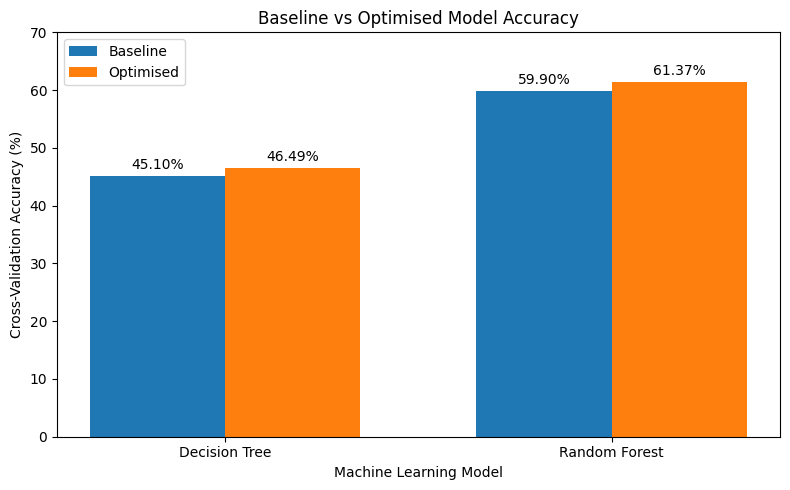

In [43]:
#Import Matplotlib for creating the bar chart
import matplotlib.pyplot as plt
import numpy as np

#Set the positions and width of the bars
x = np.arange(len(comparison_results["Model"]))
width = 0.35

#Create the chart
fig, ax = plt.subplots(figsize=(8, 5))

#Add bars for baseline and optimised accuracy
baseline_bars = ax.bar(
    x - width / 2,
    comparison_results["Baseline Accuracy (%)"],
    width,
    label="Baseline"
)

optimised_bars = ax.bar(
    x + width / 2,
    comparison_results["Optimised Accuracy (%)"],
    width,
    label="Optimised"
)

#Add chart labels and title
ax.set_xlabel("Machine Learning Model")
ax.set_ylabel("Cross-Validation Accuracy (%)")
ax.set_title("Baseline vs Optimised Model Accuracy")

#Set the model names
ax.set_xticks(x)
ax.set_xticklabels(comparison_results["Model"])

#Set the accuracy scale
ax.set_ylim(0, 70)

#Display accuracy values above each bar
ax.bar_label(baseline_bars, fmt="%.2f%%", padding=3)
ax.bar_label(optimised_bars, fmt="%.2f%%", padding=3)

#Display the legend
ax.legend()

#Adjust layout and display chart
plt.tight_layout()
plt.show()

**NB3.4.4 Computational Cost Comparison**

In this section the mean fitting times of DT and RF during hyperparameter optimisation are compared. The results gathered can be used to investigate  computational requirements of both models and whether improved classification accuracy adversly effects increased computational cost

In [44]:
# Retrieve the mean fitting times from GridSearchCV
dt_fit_time = dt_grid_search.cv_results_["mean_fit_time"].mean()
rf_fit_time = rf_grid_search.cv_results_["mean_fit_time"].mean()

# Create a DataFrame to compare the results
fit_time_results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Mean Fitting Time (seconds)": [
        dt_fit_time,
        rf_fit_time
    ]
})

# Display the comparison table
display(fit_time_results.round(4))

,Model,Mean Fitting Time (seconds)
0,Decision Tree,0.0425
1,Random Forest,0.7116


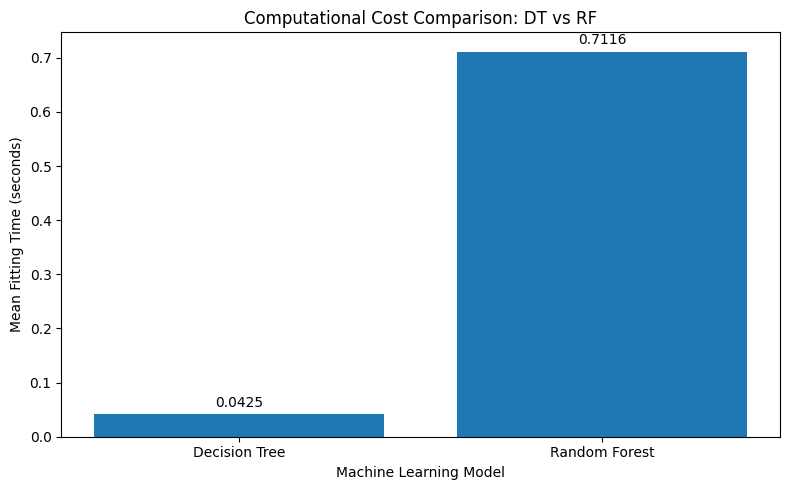

In [45]:
# Create a bar chart comparing mean fitting times
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the mean fitting times
bars = ax.bar(
    fit_time_results["Model"],
    fit_time_results["Mean Fitting Time (seconds)"]
)

# Add chart labels and title
ax.set_xlabel("Machine Learning Model")
ax.set_ylabel("Mean Fitting Time (seconds)")
ax.set_title("Computational Cost Comparison: DT vs RF")

# Display fitting times above each bar
ax.bar_label(bars, fmt="%.4f", padding=3)

# Adjust the chart layout
plt.tight_layout()

# Display the chart
plt.show()

**NB3.4.5 GridSearchCV Results Table**


This is the five highest-performing hyperparameter combinations which have been established using the GridSearchCV process for both DT and RF. The results provide evidence of how different settings affected classification accuracy during five-fold stratified cross-validation

In [46]:
#Convert the Decision Tree GridSearchCV results into a DataFrame
dt_results = pd.DataFrame(dt_grid_search.cv_results_)

#Select the relevant hyperparameters and accuracy results
dt_top_results = dt_results[[
    "param_decisiontreeclassifier__max_depth",
    "param_decisiontreeclassifier__min_samples_leaf",
    "param_decisiontreeclassifier__min_samples_split",
    "mean_test_score",
    "rank_test_score"
]].copy()

#Convert accuracy into a percentage
dt_top_results["mean_test_score"] *= 100

#Rename the columns for readability
dt_top_results.columns = [
    "Max Depth",
    "Min Samples Leaf",
    "Min Samples Split",
    "CV Accuracy (%)",
    "Rank"
]

#Sort by accuracy and display the top five combinations
dt_top_results = dt_top_results.sort_values(
    by="CV Accuracy (%)",
    ascending=False
).head(5)

display(dt_top_results.round(2))

,Max Depth,Min Samples Leaf,Min Samples Split,CV Accuracy (%),Rank
44,20,4,10,46.49,1
35,15,4,10,46.49,1
53,None,4,10,46.49,1
26,10,4,10,46.21,4
49,None,2,5,46.06,5


In [47]:
#Convert the Random Forest GridSearchCV results into a DataFrame
rf_results = pd.DataFrame(rf_grid_search.cv_results_)

#Select the relevant hyperparameters and accuracy results
rf_top_results = rf_results[[
    "param_randomforestclassifier__max_depth",
    "param_randomforestclassifier__min_samples_leaf",
    "param_randomforestclassifier__n_estimators",
    "mean_test_score",
    "rank_test_score"
]].copy()

#Convert accuracy into a percentage
rf_top_results["mean_test_score"] *= 100

#Rename the columns for readability
rf_top_results.columns = [
    "Max Depth",
    "Min Samples Leaf",
    "Number of Trees",
    "CV Accuracy (%)",
    "Rank"
]

#Sort by accuracy and display the top five combinations
rf_top_results = rf_top_results.sort_values(
    by="CV Accuracy (%)",
    ascending=False
).head(5)

display(rf_top_results.round(2))

,Max Depth,Min Samples Leaf,Number of Trees,CV Accuracy (%),Rank
45,None,1,50,61.37,1
36,20,1,50,61.23,2
28,15,1,100,60.80,3
27,15,1,50,60.80,4
20,10,1,200,60.80,5


**NB3.5 Learning Curves**

The idea of this section is to create relevant learning curves for both DT and RF

In [48]:
#Establish five-fold stratified cross-validation
cv_learning = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

#Establish the training dataset sizes
training_sizes = np.linspace(0.2, 1.0, 5)


**NB3.5.1 Decision Tree learning curve**

This section generates a learning curve for the
DT model

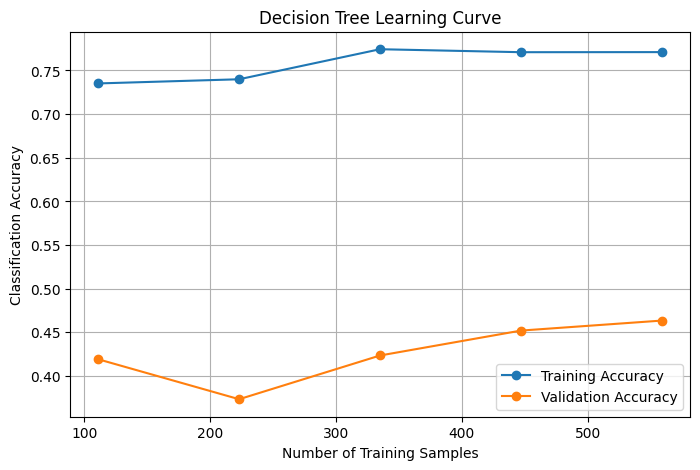

In [49]:
#Generate the learning curve for the optimised Decision Tree
dt_sizes, dt_train_scores, dt_val_scores = learning_curve(
    dt_grid_search.best_estimator_,
    X_train,
    y_train,
    train_sizes=training_sizes,
    cv=cv_learning,
    scoring="accuracy",
    n_jobs=-1
)

#Calculate the mean training and validation accuracy
dt_train_mean = np.mean(dt_train_scores, axis=1)
dt_val_mean = np.mean(dt_val_scores, axis=1)

#Create the Decision Tree learning curve
plt.figure(figsize=(8, 5))

plt.plot(dt_sizes, dt_train_mean,
         marker="o", label="Training Accuracy")

plt.plot(dt_sizes, dt_val_mean,
         marker="o", label="Validation Accuracy")

plt.title("Decision Tree Learning Curve")
plt.xlabel("Number of Training Samples")
plt.ylabel("Classification Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [50]:
# Display Decision Tree learning curve results
import pandas as pd

dt_learning_results = pd.DataFrame({
    "Training Samples": dt_sizes,
    "Training Accuracy (%)": np.round(dt_train_mean * 100, 2),
    "Validation Accuracy (%)": np.round(dt_val_mean * 100, 2)
})

display(dt_learning_results)

,Training Samples,Training Accuracy (%),Validation Accuracy (%)
0,111,73.51,41.92
1,223,73.99,37.34
2,335,77.43,42.35
3,447,77.09,45.20
4,559,77.10,46.35


**NB3.5.2 Random Forest Learning Curve**

This section generates a learning curve for the RF model

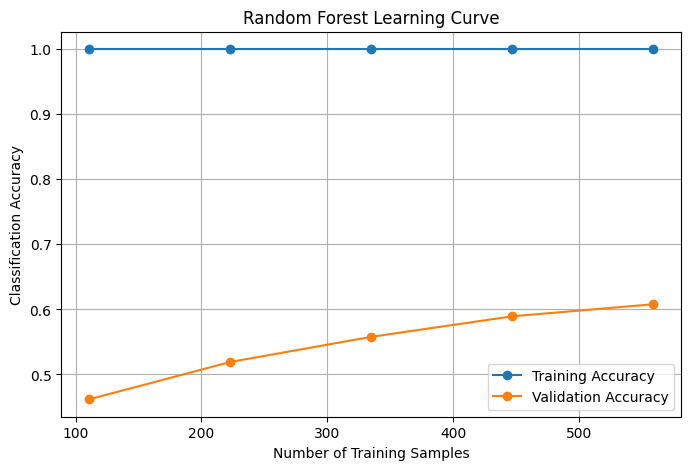

In [51]:
#Generate the learning curve for the optimised Random Forest
rf_sizes, rf_train_scores, rf_val_scores = learning_curve(
    rf_grid_search.best_estimator_,
    X_train,
    y_train,
    train_sizes=training_sizes,
    cv=cv_learning,
    scoring="accuracy",
    n_jobs=-1
)

#Calculate mean training and validation accuracy
rf_train_mean = np.mean(rf_train_scores, axis=1)
rf_val_mean = np.mean(rf_val_scores, axis=1)

#Create the Random Forest learning curve
plt.figure(figsize=(8, 5))

plt.plot(rf_sizes, rf_train_mean,
         marker="o", label="Training Accuracy")

plt.plot(rf_sizes, rf_val_mean,
         marker="o", label="Validation Accuracy")

plt.title("Random Forest Learning Curve")
plt.xlabel("Number of Training Samples")
plt.ylabel("Classification Accuracy")
plt.legend()
plt.grid(True)
plt.show()


In [52]:
# Display Random Forest learning curve results
rf_learning_results = pd.DataFrame({
    "Training Samples": rf_sizes,
    "Training Accuracy (%)": np.round(rf_train_mean * 100, 2),
    "Validation Accuracy (%)": np.round(rf_val_mean * 100, 2)
})

display(rf_learning_results)

,Training Samples,Training Accuracy (%),Validation Accuracy (%)
0,111,100.0,46.20
1,223,100.0,51.92
2,335,100.0,55.79
3,447,100.0,58.94
4,559,100.0,60.80


**NB4 Model Testing and Results**

This section goes through testing on the unseen test data using both DT and RF models. It uses the evaluation metrics established in Section B4.2 to determine the performance of each model, with the results also being presented in confusion matrices.

NB4.3 Decision Tree Testing Results

In [53]:
#Use the best Decision Tree model from GridSearchCV
dt_best = dt_grid_search.best_estimator_

#Predict genres using the untouched test dataset
dt_predictions = dt_best.predict(X_test)

#Confirm the number of test recordings
print("Test recordings:", len(y_test))
print("Predictions made:", len(dt_predictions))

Test recordings: 300
Predictions made: 300


**Decision Tree Evaluation Metrics**

In [54]:
#Calculate the Decision Tree evaluation metrics
#Calculates the percentage of correctly classified recordings
dt_accuracy = accuracy_score(y_test, dt_predictions)

#Measures how often predicted genres are correct
dt_precision = precision_score(
    y_test, dt_predictions, average='macro', zero_division=0
)

#Measures how successfully the model identifies recordings belonging to each genre
dt_recall = recall_score(
    y_test, dt_predictions, average='macro', zero_division=0
)

#Calculates the harmonic mean of precision and recall
dt_f1 = f1_score(
    y_test, dt_predictions, average='macro', zero_division=0
)

#Display results as percentages
print(f"Decision Tree Accuracy: {dt_accuracy * 100:.2f}%")
print(f"Decision Tree Precision: {dt_precision * 100:.2f}%")
print(f"Decision Tree Recall: {dt_recall * 100:.2f}%")
print(f"Decision Tree F1-score: {dt_f1 * 100:.2f}%")

Decision Tree Accuracy: 49.33%
Decision Tree Precision: 48.51%
Decision Tree Recall: 49.33%
Decision Tree F1-score: 48.45%


In [55]:
#Create a table of Decision Tree test results
dt_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Result (%)": [
        round(dt_accuracy * 100, 2),
        round(dt_precision * 100, 2),
        round(dt_recall * 100, 2),
        round(dt_f1 * 100, 2)
    ]
})

#Display the results table
display(dt_results)

,Metric,Result (%)
0,Accuracy,49.33
1,Precision,48.51
2,Recall,49.33
3,F1-score,48.45


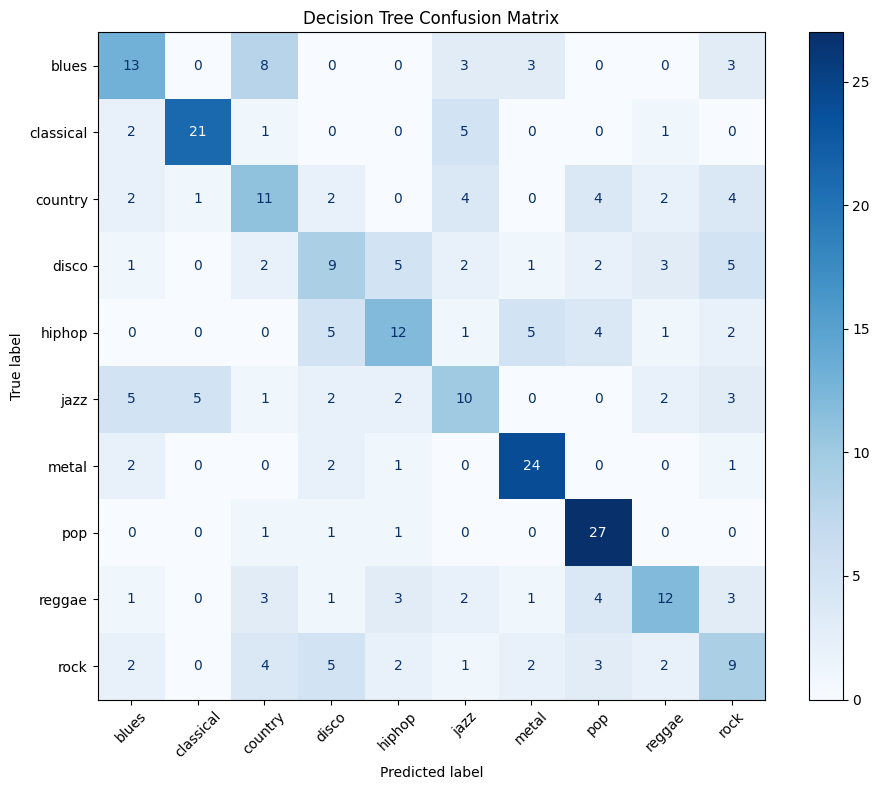

In [56]:
#Create the Decision Tree confusion matrix
dt_cm = confusion_matrix(y_test, dt_predictions)

#Display the confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=dt_cm,
    display_labels=dt_best.classes_
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

NB4.4 Random Forest Testing Results

In [57]:
#Use the best Random Forest model from GridSearchCV
rf_best = rf_grid_search.best_estimator_

#Predict genres using the untouched test dataset
rf_predictions = rf_best.predict(X_test)

#Confirm the number of test recordings
print("Test recordings:", len(y_test))
print("Predictions made:", len(rf_predictions))

Test recordings: 300
Predictions made: 300


**Random Forest Evaluation Metrics**

In [58]:
#Calculate the Random Forest evaluation metrics
rf_accuracy = accuracy_score(y_test, rf_predictions)

rf_precision = precision_score(
    y_test, rf_predictions, average='macro', zero_division=0
)

rf_recall = recall_score(
    y_test, rf_predictions, average='macro', zero_division=0
)

rf_f1 = f1_score(
    y_test, rf_predictions, average='macro', zero_division=0
)

#Display results as percentages
print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")
print(f"Random Forest Precision: {rf_precision * 100:.2f}%")
print(f"Random Forest Recall: {rf_recall * 100:.2f}%")
print(f"Random Forest F1-score: {rf_f1 * 100:.2f}%")


Random Forest Accuracy: 56.00%
Random Forest Precision: 55.67%
Random Forest Recall: 56.00%
Random Forest F1-score: 55.18%


In [59]:
#Create a table of Random Forest test results
rf_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Result (%)": [
        round(rf_accuracy * 100, 2),
        round(rf_precision * 100, 2),
        round(rf_recall * 100, 2),
        round(rf_f1 * 100, 2)
    ]
})

#Display the results table
display(rf_results)

,Metric,Result (%)
0,Accuracy,56.00
1,Precision,55.67
2,Recall,56.00
3,F1-score,55.18


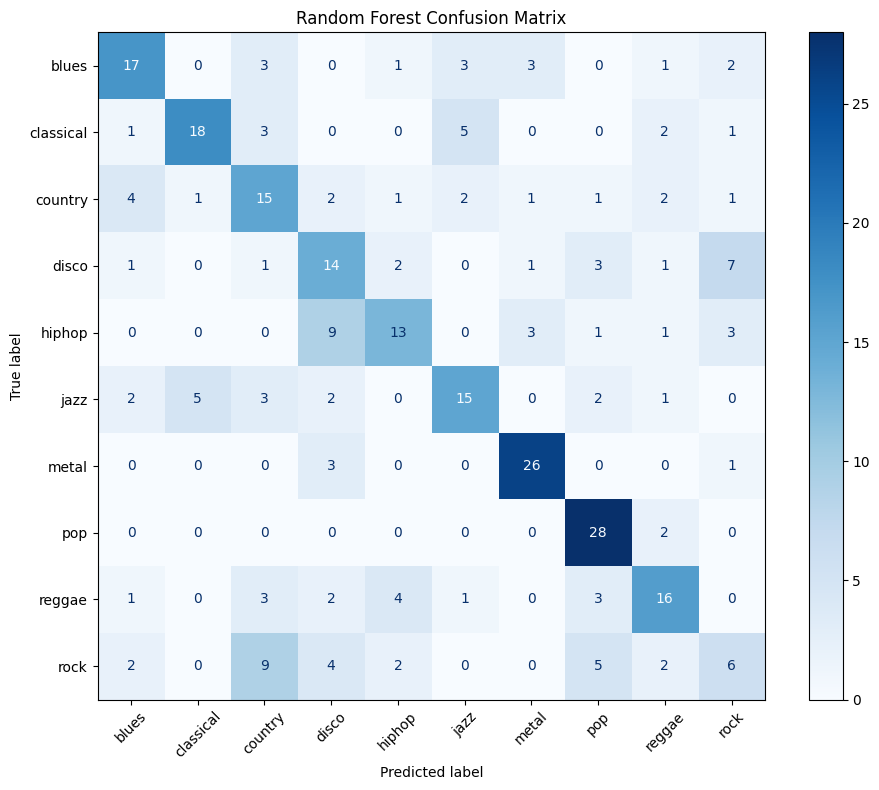

In [60]:
#Create the Random Forest confusion matrix
rf_cm = confusion_matrix(y_test, rf_predictions)

#Display the confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=rf_best.classes_
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()


**Standard Deviation**

In [61]:
# Obtain standard deviation from the best GridSearchCV results
dt_sd = dt_grid_search.cv_results_["std_test_score"][dt_grid_search.best_index_]
rf_sd = rf_grid_search.cv_results_["std_test_score"][rf_grid_search.best_index_]

print(f"DT standard deviation: {dt_sd * 100:.2f} percentage points")
print(f"RF standard deviation: {rf_sd * 100:.2f} percentage points")

DT standard deviation: 2.20 percentage points
RF standard deviation: 1.31 percentage points


**TBC Reproducibility and Project Documentation**

This section creates the project documentation and records the Python dependencies required to reproduce the implementation and testing results

A requirements file is created to document the Python packages required to reproduce the implementation

In [62]:
%%writefile requirements.txt
numpy TBC
pandas TBC
scikit-learn TBC
matplotlib TBC
jupyter TBC

Writing requirements.txt


A README file is created to explain the project, dataset, algorithms and instructions for reproducing the results

In [63]:
%%writefile README.md
# GTZAN Dataset

## Project Overview123456
TBC

TBC

## Dataset
TBC

TBC

## Algorithms
TBC

## Testing and Evaluation
TBC

## Requirements
TBC

    pip install -r requirements.txt

## Running the Notebook
TBC

## Reproducibility
TBC

TBC


Writing README.md
